In [1]:
import torch
from torch.utils.data import DataLoader

from deep_models.vae import SparseConvVAE, plot_latent_usage
from deep_models.vae_train import *
from deep_models.data import load_folds, make_splits, S00MILDataset

In [2]:
dev_path = "/dmj/fizmed/mmarzec/licencjat_neuro/DL-NS/split_data/one_site/splits/s00_developmental.npz"
split_k = 7

In [3]:
developamental_folds = load_folds(dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")
device = torch.device("cuda")

train=1085  val=132  test=136


In [4]:
train_ds = S00MILDataset(train_idx, max_instances=150, train=True, return_cond=True)
val_ds   = S00MILDataset(val_idx,   max_instances=150, train=False, return_cond=True)

train_loader = DataLoader(train_ds, batch_size=10, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=10, shuffle=False, num_workers=2, pin_memory=True)

# Build & initialize model

In [5]:
model = SparseConvVAE(
    latent=64,
    alpha=0.1,          
    cond_dim=2,         
    cond_in_encoder=True,
).to(device)
init_model(model, train_loader)  

SparseConvVAE(
  (encoder): Sequential(
    (0): Conv2d(5, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=66, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=66, out_features=64, bias=True)
  (fc): Linear(in_features=66, out_features=64, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(16, 5, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  )
  (fc_gamma): Linear(in_features=66, out_features=64, bias=True)
)

# Train the model & save the best epoch's version

In [6]:
history = fit(
    model,
    train_loader,
    val_loader,
    device,
    epochs=150,
    lr=1e-3,
    beta_max=5e-4,
    anneal_start=50,
    anneal_epochs=50,
    ckpt_path=f"best_scvae_fold{split_k}.pt")

epoch   1/150  beta 0.00e+00  train 0.7662  val 0.6860  recon 0.6860  MSE 0.00050  KL 160.88  R2 0.111
epoch   2/150  beta 0.00e+00  train 0.5985  val 0.5542  recon 0.5542  MSE 0.00041  KL 310.96  R2 0.282
epoch   3/150  beta 0.00e+00  train 0.5035  val 0.4613  recon 0.4613  MSE 0.00034  KL 414.37  R2 0.402
epoch   4/150  beta 0.00e+00  train 0.4152  val 0.3914  recon 0.3914  MSE 0.00029  KL 430.22  R2 0.493
epoch   5/150  beta 0.00e+00  train 0.3691  val 0.3536  recon 0.3536  MSE 0.00026  KL 433.34  R2 0.542
epoch   6/150  beta 0.00e+00  train 0.3384  val 0.3295  recon 0.3295  MSE 0.00024  KL 428.28  R2 0.573
epoch   7/150  beta 0.00e+00  train 0.3172  val 0.3112  recon 0.3112  MSE 0.00023  KL 439.59  R2 0.597
epoch   8/150  beta 0.00e+00  train 0.3015  val 0.2960  recon 0.2960  MSE 0.00022  KL 445.66  R2 0.616
epoch   9/150  beta 0.00e+00  train 0.2877  val 0.2826  recon 0.2826  MSE 0.00021  KL 454.84  R2 0.634
epoch  10/150  beta 0.00e+00  train 0.2740  val 0.2700  recon 0.2700  MSE

# Evaluate training history

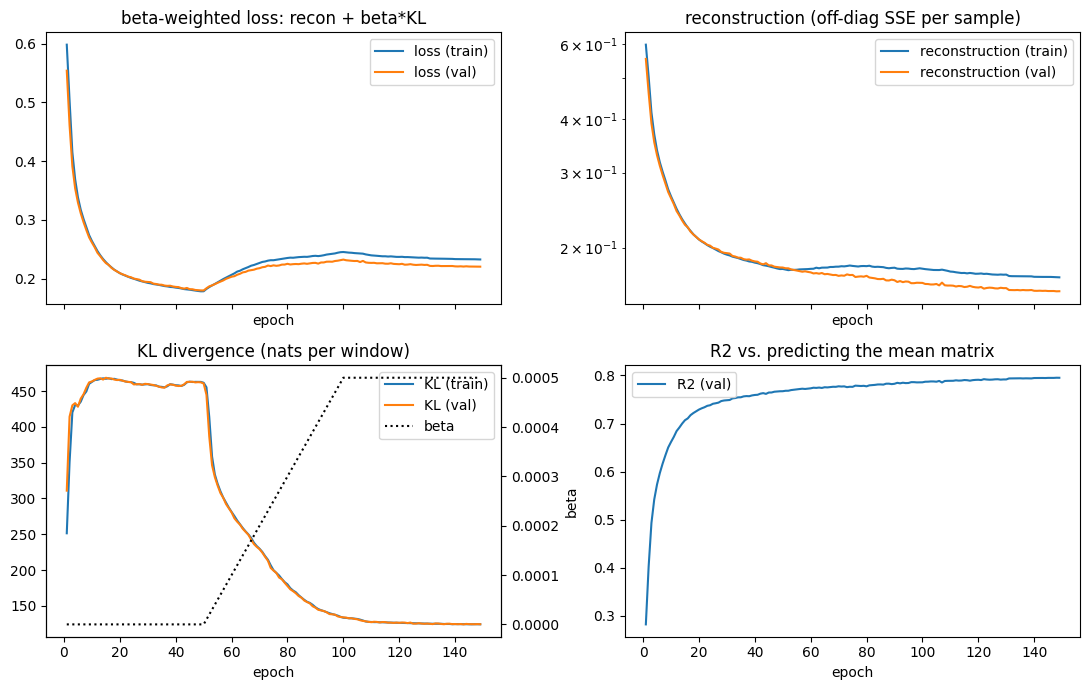

In [7]:
g = plot_history(history, skip=1)
g.show()